# Income and Housing Costs by Census Tract — ACS 2020–2024 5-Year Estimates

This notebook pulls **tract-level** data from the U.S. Census Bureau's American Community Survey (ACS) 5-Year API for 2024 and draws heat maps (choropleths) of five measures, each for **every tract in the United States** (lower 48, with Alaska and Hawaii insets) and **every tract in North Carolina**:

| Measure | ACS table | Universe |
|---|---|---|
| Median household income | B19013 | All households |
| Median gross rent (rent + utilities) | B25064 | Renter-occupied units paying cash rent |
| Median gross rent as % of household income | B25071 | Renter-occupied units paying cash rent |
| Median home value | B25077 | Owner-occupied units |
| Median monthly housing costs | B25105 | All occupied units (owners and renters) |

Each measure has its own color scale, and the national and North Carolina maps of the same measure share that scale, so they can be compared directly.

**Data sources**
- ACS 5-Year Detailed Tables API: `https://api.census.gov/data/2024/acs/acs5`
- 2024 Cartographic Boundary Files (1:500k): tracts, counties, and states from `https://www2.census.gov/geo/tiger/GENZ2024/shp/`

**Before you run it:** put your Census API key in the configuration cell below.

**Runtime notes:** the first run makes about 52 API calls (one per state plus DC) and downloads roughly 100 MB of boundary files. Everything is cached in a `data/` folder, so later runs are fast and make no API calls. Each national map draws about 85,000 polygons and can take up to a minute to render, so the full set of 10 maps takes several minutes.

In [13]:
# If any packages are missing, uncomment and run this line once, then restart the kernel:
# %pip install requests pandas numpy geopandas pyogrio matplotlib

import os
import time
from pathlib import Path

import numpy as np
import pandas as pd
import requests
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from matplotlib.colors import BoundaryNorm, ListedColormap
from matplotlib.cm import ScalarMappable
from matplotlib.patches import Patch

pd.set_option("display.max_columns", 50)

## 1. Configuration

Fill in your API key here. To avoid committing the key to a shared repo, you can instead set an environment variable named `CENSUS_API_KEY` before starting Jupyter, and leave the placeholder as is.

In [14]:
# ── Census API key ────────────────────────────────────────────────────────────
CENSUS_API_KEY = os.environ.get("CENSUS_API_KEY", "641a1469f686a5f10d4b12b09b248d7a285813ed")   # <-- paste your key here

# ── Dataset ───────────────────────────────────────────────────────────────────
YEAR = 2024                    # ACS 5-year release: 2020–2024 estimates
BASE_URL = f"https://api.census.gov/data/{YEAR}/acs/acs5"   # Detailed Tables endpoint

# Variables pulled for every tract: {Census variable ID: friendly column name}.
# Add more as the project grows (the API allows up to 50 per request).
# Browse variables: https://api.census.gov/data/2024/acs/acs5/variables.html
VARIABLES = {
    # Mapped measures
    "B19013_001E": "median_hh_income",              # Median household income (2024 dollars)
    "B25064_001E": "median_gross_rent",             # Median gross rent (contract rent + utilities)
    "B25071_001E": "rent_pct_income",               # Median gross rent as % of household income
    "B25077_001E": "median_home_value",             # Median value, owner-occupied units
    "B25105_001E": "median_monthly_housing_cost",   # Median monthly housing costs, all occupied units
    # Supporting fields (counts used to weight averages, plus a margin of error for quality checks)
    "B19013_001M": "median_hh_income_moe",
    "B01003_001E": "total_population",
    "B25003_001E": "occupied_units",                # = households
    "B25003_002E": "owner_units",
    "B25003_003E": "renter_units",
}

INCLUDE_PUERTO_RICO = False    # ACS 5-year covers Puerto Rico; set True to add it as a map inset
NC_FIPS = "37"                 # North Carolina

# ── Folders ───────────────────────────────────────────────────────────────────
DATA_DIR = Path("data");     DATA_DIR.mkdir(exist_ok=True)
FIG_DIR = Path("figures");   FIG_DIR.mkdir(exist_ok=True)
ACS_CACHE = DATA_DIR / f"acs5_{YEAR}_tracts_raw.csv"

## 2. Pull tract data from the Census API

The API returns tracts one state at a time (`for=tract:*&in=state:XX&in=county:*`), so the code loops over all states plus DC. Results are cached to `data/`. If you add variables to `VARIABLES`, the cache is detected as stale and refreshed automatically (so if you ran an earlier version of this notebook, the first run will fetch again).

In [15]:
def _check_key():
    if not CENSUS_API_KEY or CENSUS_API_KEY == "YOUR_API_KEY_HERE":
        raise ValueError(
            "Set CENSUS_API_KEY in the configuration cell (or as an environment variable) "
            "before fetching data. Request a free key at https://api.census.gov/data/key_signup.html"
        )


def census_get(params, retries=4):
    # Call the ACS API and return the JSON rows (first row is the header).
    params = list(params) + [("key", CENSUS_API_KEY)]
    for attempt in range(retries):
        wait = 2 ** attempt * 2
        try:
            r = requests.get(BASE_URL, params=params, timeout=90)
        except requests.RequestException as e:
            print(f"  network error ({type(e).__name__}); retrying in {wait}s")
            time.sleep(wait)
            continue
        if r.status_code == 200:
            try:
                return r.json()
            except ValueError:
                # An invalid or not-yet-activated key returns an HTML page instead of JSON.
                raise RuntimeError(
                    "The Census API did not return JSON. This usually means the API key is invalid "
                    "or hasn't been activated yet (check your email for the activation link).\n"
                    f"Response begins: {r.text[:200]!r}"
                )
        if r.status_code in (429, 500, 502, 503, 504):
            print(f"  HTTP {r.status_code}; retrying in {wait}s")
            time.sleep(wait)
            continue
        raise RuntimeError(f"Census API error {r.status_code}: {r.text[:300]}")
    raise RuntimeError("Census API request failed after several retries.")


def list_states():
    rows = census_get([("get", "NAME"), ("for", "state:*")])
    states = pd.DataFrame(rows[1:], columns=rows[0])
    if not INCLUDE_PUERTO_RICO:
        states = states[states["state"] != "72"]
    return states.sort_values("state").reset_index(drop=True)


def fetch_state_tracts(state_fips):
    rows = census_get([
        ("get", ",".join(["NAME", *VARIABLES])),
        ("for", "tract:*"),
        ("in", f"state:{state_fips}"),
        ("in", "county:*"),
    ])
    return pd.DataFrame(rows[1:], columns=rows[0])


def load_or_fetch_acs():
    if ACS_CACHE.exists():
        cached = pd.read_csv(ACS_CACHE, dtype=str)   # dtype=str keeps leading zeros in FIPS codes
        if set(VARIABLES).issubset(cached.columns):
            print(f"Loaded {len(cached):,} tracts from cache ({ACS_CACHE})")
            return cached
        print("Cached file is missing some variables; fetching fresh data.")

    _check_key()
    states = list_states()
    frames = []
    for i, row in states.iterrows():
        print(f"[{i + 1:2d}/{len(states)}] {row['NAME']:<22}", end="")
        df = fetch_state_tracts(row["state"])
        print(f"{len(df):>6,} tracts")
        frames.append(df)
        time.sleep(0.2)   # be polite to the API
    raw = pd.concat(frames, ignore_index=True)
    raw.to_csv(ACS_CACHE, index=False)
    print(f"\nSaved {len(raw):,} tracts to {ACS_CACHE}")
    return raw


raw = load_or_fetch_acs()
raw.head()

Loaded 84,401 tracts from cache (data\acs5_2024_tracts_raw.csv)


,NAME,B19013_001E,B25064_001E,B25071_001E,B25077_001E,B25105_001E,B19013_001M,B01003_001E,B25003_001E,B25003_002E,B25003_003E,state,county,tract
0,Census Tract 201; Autauga County; Alabama,63237,1049,24.1,188800,993,5873,1781,736,502,234,01,001,020100
1,Census Tract 202; Autauga County; Alabama,61229,897,34.2,154900,916,9454,1941,592,432,160,01,001,020200
2,Census Tract 203; Autauga County; Alabama,63939,1035,36.7,147700,1015,10242,3425,1235,822,413,01,001,020300
3,Census Tract 204; Autauga County; Alabama,69348,1048,24.6,181700,756,18043,3948,1638,1258,380,01,001,020400
4,Census Tract 205.01; Autauga County; Alabama,88965,1614,28.8,199000,1309,6635,4444,1907,1325,582,01,001,020501


## 3. Clean the data

- Build the 11-digit tract **GEOID** (state + county + tract) used to join with the map boundaries.
- Convert values to numbers. The ACS uses large negative codes such as `-666666666` to mean "estimate not available" (typically tracts with too few households, renters, or owners to estimate), so negative values become missing.
- Medians are **top- and bottom-coded**. For example, income tops out at 250,001 ("$250,000 or more"), home value at 2,000,001 ("$2,000,000 or more"), and rent as a share of income at 50.1 ("50% or more"). The color scales below put top-coded values in the highest bin.

In [16]:
acs = raw.copy()
acs["GEOID"] = acs["state"] + acs["county"] + acs["tract"]

for var_id, name in VARIABLES.items():
    values = pd.to_numeric(acs[var_id], errors="coerce")
    acs[name] = values.mask(values < 0)    # ACS "not available" codes are all negative

acs = acs[["GEOID", "NAME", "state", "county", "tract", *VARIABLES.values()]]
acs.to_csv(DATA_DIR / f"acs5_{YEAR}_tracts_clean.csv", index=False)

print(f"{len(acs):,} tracts")
acs.describe().round(1)

84,401 tracts


,median_hh_income,median_gross_rent,rent_pct_income,median_home_value,median_monthly_housing_cost,median_hh_income_moe,total_population,occupied_units,owner_units,renter_units
count,82913.0,79285.0,80714.0,81256.0,83126.0,82355.0,84401.0,84401.0,84401.0,84401.0
mean,86359.7,1477.1,31.1,398396.7,1479.9,18763.1,3967.3,1530.9,997.6,533.3
std,41178.4,647.1,9.1,316400.2,681.9,12061.3,1832.1,683.9,585.9,467.3
min,2499.0,99.0,9.0,9999.0,181.0,209.0,0.0,0.0,0.0,0.0
25%,58108.0,978.0,24.7,190900.0,965.0,10596.0,2714.0,1067.0,584.0,200.0
50%,77449.0,1337.0,29.8,308500.0,1346.0,15916.0,3773.0,1463.0,938.0,405.0
75%,105000.0,1821.0,36.2,491400.0,1842.0,23702.0,4981.0,1919.0,1338.0,733.0
max,250001.0,3501.0,51.0,2000001.0,4001.0,171371.0,44364.0,12756.0,11482.0,8189.0


## 4. Map settings for each measure

Each entry defines the title, the color bins, how tick labels are formatted, the colormap, and which household count to use when weighting averages.

- Bins are fixed dollar (or percent) cutoffs rather than a continuous scale, because these measures are strongly right-skewed. A linear scale would make most of the country look the same color.
- The last bin is open-ended: anything at or above the second-to-last cutoff, including top-coded values, gets the top color.
- Rent as a share of income uses a **diverging** scale centered on **30%**, the standard threshold for being "cost-burdened." Blue tracts are below it and red tracts are above it.
- `outline` (optional) sets the state and county border color; it defaults to white.
- Edit the `breaks` lists to tune the bins once you've seen the real distributions (the summary table in the next step helps).

In [17]:
def money_short(v):        # $35k, $1.5M
    if v <= 0:
        return "$0"
    return f"${v / 1e6:g}M" if v >= 1e6 else f"${v / 1000:,.0f}k"


def money_full(v):         # $1,200
    return f"${v:,.0f}"


def pct(v):                # 30%
    return f"{v:.0f}%"


MAP_SPECS = {
    "median_hh_income": dict(
        title="Median Household Income",
        label="Median household income (2024 dollars)",
        table="B19013",
        breaks=[0, 35_000, 50_000, 65_000, 80_000, 100_000, 125_000, 150_000, 200_000, 250_000],
        fmt=money_short, top_label="$250k+",
        cmap="magma", cmap_range=(0.08, 0.97),
        weight="occupied_units",
    ),
    "median_gross_rent": dict(
        title="Median Gross Rent",
        label="Median monthly gross rent, including utilities (2024 dollars)",
        table="B25064",
        breaks=[0, 800, 1_000, 1_200, 1_400, 1_600, 1_900, 2_200, 2_700, 3_500],
        fmt=money_full, top_label="$3,500+",
        cmap="viridis", cmap_range=(0.0, 1.0),
        weight="renter_units",
    ),
    # "rent_pct_income": dict(
    #     title="Rent as a Share of Household Income",
    #     label="Median gross rent as % of household income (30%+ = cost-burdened)",
    #     table="B25071",
    #     breaks=[0, 20, 24, 27, 30, 33, 37, 42, 50],
    #     fmt=pct, top_label="50%+",
    #     cmap="RdYlBu_r", cmap_range=(0.0, 1.0),
    #     outline="#555555",      # white borders disappear against the pale middle colors
    #     weight="renter_units",
    # ),
        "rent_pct_income": dict(
        title="Rent as a Share of Household Income",
        label="Median gross rent as % of household income (30%+ = cost-burdened)",
        table="B25071",
        breaks=[0, 20, 25, 30, 35, 40, 50],
        fmt=pct, top_label="50%+",
        # Hand-picked from ColorBrewer RdBu with the pale center shades removed:
        # 3 blues below the 30% threshold, 3 reds above it, so every bin is distinct.
        colors=["#2166ac", "#4393c3", "#92c5de", "#f4a582", "#d6604d", "#b2182b"],
        outline="#555555",
        weight="renter_units",
    ),
    "median_home_value": dict(
        title="Median Home Value",
        label="Median value of owner-occupied homes (2024 dollars)",
        table="B25077",
        breaks=[0, 100_000, 150_000, 200_000, 250_000, 325_000, 400_000, 500_000, 750_000, 1_000_000, 2_000_000],
        fmt=money_short, top_label="$2M+",
        cmap="plasma", cmap_range=(0.0, 0.95),
        weight="owner_units",
    ),
    "median_monthly_housing_cost": dict(
        title="Median Monthly Housing Costs",
        label="Median monthly housing costs, owners and renters (2024 dollars)",
        table="B25105",
        breaks=[0, 600, 800, 1_000, 1_200, 1_500, 1_800, 2_200, 2_800, 4_000],
        fmt=money_full, top_label="$4,000+",
        cmap="YlGnBu", cmap_range=(0.12, 1.0),
        outline="#555555",
        weight="occupied_units",
    ),
}

# Draw all of them, or list just the ones you want, e.g. ["median_gross_rent"]
MAPS_TO_DRAW = list(MAP_SPECS)

### Summary statistics: United States vs. North Carolina

Each tract reports a *median*, so averaging across tracts describes the typical tract, not the typical household. The weighted average gives more influence to tracts with more households in the relevant group (renters for rent, owners for home value, all households otherwise), which gets closer to the typical household's experience.

In [18]:
def describe_measure(df, col, weight_col):
    v = df[col]
    ok = v.notna() & (df[weight_col] > 0)
    return {
        "Tracts with data": v.notna().sum(),
        "Median of tracts": v.median(),
        "Mean of tracts": v.mean(),
        "Household-weighted mean": np.average(v[ok], weights=df.loc[ok, weight_col]) if ok.any() else np.nan,
        "10th percentile": v.quantile(0.10),
        "90th percentile": v.quantile(0.90),
    }


rows = []
nc_acs = acs[acs["state"] == NC_FIPS]
for col, spec in MAP_SPECS.items():
    for place, df in [("United States", acs), ("North Carolina", nc_acs)]:
        rows.append({"Measure": spec["title"], "Area": place, **describe_measure(df, col, spec["weight"])})

summary = pd.DataFrame(rows).set_index(["Measure", "Area"])

# Display: whole numbers, except one decimal for the rent-burden percentages
shown = summary.apply(lambda c: c.map(lambda v: f"{v:,.0f}"))
pct_rows = summary.index.get_level_values("Measure") == MAP_SPECS["rent_pct_income"]["title"]
stat_cols = summary.columns[1:]
shown.loc[pct_rows, stat_cols] = summary.loc[pct_rows, stat_cols].apply(lambda c: c.map(lambda v: f"{v:.1f}%"))
shown

Tracts with data  \
Measure                             Area                              
Median Household Income             United States            82,913   
                                    North Carolina            2,634   
Median Gross Rent                   United States            79,285   
                                    North Carolina            2,539   
Rent as a Share of Household Income United States            80,714   
                                    North Carolina            2,586   
Median Home Value                   United States            81,256   
                                    North Carolina            2,601   
Median Monthly Housing Costs        United States            83,126   
                                    North Carolina            2,636   

                                                   Median of tracts  \
Measure                             Area                              
Median Household Income             United States            77,449   
                                    North Carolina           68,502   
Median Gross Rent                   United States             1,337   
                                    North Carolina            1,118   
Rent as a Share of Household Income United States             29.8%   
                                    North Carolina            28.9%   
Median Home Value                   United States           308,500   
                                    North Carolina          257,300   
Median Monthly Housing Costs        United States             1,346   
                                    North Carolina            1,100   

                                                   Mean of tracts  \
Measure                             Area                            
Median Household Income             United States          86,360   
                                    North Carolina         76,308   
Median Gross Rent                   United States           1,477   
                                    North Carolina          1,220   
Rent as a Share of Household Income United States           31.1%   
                                    North Carolina          29.9%   
Median Home Value                   United States         398,397   
                                    North Carolina        305,221   
Median Monthly Housing Costs        United States           1,480   
                                    North Carolina          1,185   

                                                   Household-weighted mean  \
Measure                             Area                                     
Median Household Income             United States                   89,014   
                                    North Carolina                  78,654   
Median Gross Rent                   United States                    1,511   
                                    North Carolina                   1,257   
Rent as a Share of Household Income United States                    31.9%   
                                    North Carolina                   30.7%   
Median Home Value                   United States                  404,377   
                                    North Carolina                 320,407   
Median Monthly Housing Costs        United States                    1,531   
                                    North Carolina                   1,228   

                                                   10th percentile  \
Measure                             Area                             
Median Household Income             United States           44,063   
                                    North Carolina          42,711   
Median Gross Rent                   United States              791   
                                    North Carolina             750   
Rent as a Share of Household Income United States            20.4%   
                                    North Carolina           19.5%   
Median Home Value  

## 5. Download tract, county, and state boundaries

Cartographic boundary files are simplified shapes designed for thematic maps like these. They're downloaded once and cached.

In [19]:
GEO_BASE = f"https://www2.census.gov/geo/tiger/GENZ{YEAR}/shp"


def get_boundaries(layer):
    # layer is "tract", "county", or "state"
    fname = f"cb_{YEAR}_us_{layer}_500k.zip"
    path = DATA_DIR / fname
    if not path.exists():
        print(f"Downloading {fname} ...")
        with requests.get(f"{GEO_BASE}/{fname}", stream=True, timeout=600) as r:
            r.raise_for_status()
            with open(path, "wb") as f:
                for chunk in r.iter_content(chunk_size=1 << 20):
                    f.write(chunk)
    return gpd.read_file(path)


keep_states = set(acs["state"])     # the 50 states + DC (+ PR if enabled)

tracts_geo = get_boundaries("tract")
tracts_geo = tracts_geo[tracts_geo["STATEFP"].isin(keep_states)]
counties_geo = get_boundaries("county")
counties_geo = counties_geo[counties_geo["STATEFP"].isin(keep_states)]
states_geo = get_boundaries("state")
states_geo = states_geo[states_geo["STATEFP"].isin(keep_states)]

# Join ACS values onto tract shapes; drop water-only tracts (no land, no residents)
gdf = tracts_geo[["GEOID", "STATEFP", "ALAND", "geometry"]].merge(acs, on="GEOID", how="left")
gdf = gdf[pd.to_numeric(gdf["ALAND"]) > 0]

unmatched = len(set(acs["GEOID"]) - set(tracts_geo["GEOID"]))
print(f"{len(gdf):,} tract shapes; ACS tracts without a matching shape: {unmatched}")
print((gdf[list(MAP_SPECS)].notna().sum()).rename("tracts with data").to_frame())

84,094 tract shapes; ACS tracts without a matching shape: 296
                             tracts with data
median_hh_income                        82913
median_gross_rent                       79285
rent_pct_income                         80714
median_home_value                       81256
median_monthly_housing_cost             83126


## 6. Projections and plotting helpers

Shapes are projected once here and reused by every map:
- Lower 48: Albers equal-area (EPSG:5070)
- Alaska and Hawaii insets: their own Albers projections (not to scale relative to the mainland)
- North Carolina: NC State Plane (EPSG:32119)

In [20]:
CONUS_CRS, ALASKA_CRS, HAWAII_CRS, PR_CRS, NC_CRS = "EPSG:5070", "EPSG:3338", "ESRI:102007", "EPSG:32161", "EPSG:32119"
OUTSIDE_CONUS = ["02", "15", "72"]
NO_DATA_COLOR = "#cfcfcf"
SOURCE_NOTE = (f"Source: U.S. Census Bureau, American Community Survey {YEAR - 4}–{YEAR} 5-Year Estimates "
               f"(Table {{table}}); {YEAR} Cartographic Boundary Files.")

# National layers
lower48 = gdf[~gdf["STATEFP"].isin(OUTSIDE_CONUS)].to_crs(CONUS_CRS)
states48 = states_geo[~states_geo["STATEFP"].isin(OUTSIDE_CONUS)].to_crs(CONUS_CRS)

inset_specs = [("02", ALASKA_CRS, [0.02, 0.11, 0.24, 0.24]),
               ("15", HAWAII_CRS, [0.25, 0.13, 0.13, 0.11])]
if INCLUDE_PUERTO_RICO:
    inset_specs.append(("72", PR_CRS, [0.39, 0.13, 0.08, 0.06]))
insets = [(gdf[gdf["STATEFP"] == fips].to_crs(crs),
           states_geo[states_geo["STATEFP"] == fips].to_crs(crs), pos)
          for fips, crs, pos in inset_specs]

# North Carolina layers
nc = gdf[gdf["STATEFP"] == NC_FIPS].to_crs(NC_CRS)
nc_counties = counties_geo[counties_geo["STATEFP"] == NC_FIPS].to_crs(NC_CRS)
nc_outline = states_geo[states_geo["STATEFP"] == NC_FIPS].to_crs(NC_CRS)

# "side" sets which side of the dot each label sits on, to keep nearby labels from colliding
cities = pd.DataFrame({
    "name": ["Charlotte", "Raleigh", "Greensboro", "Durham", "Winston-Salem",
             "Fayetteville", "Wilmington", "Asheville"],
    "lat": [35.2271, 35.7796, 36.0726, 35.9940, 36.0999, 35.0527, 34.2104, 35.5951],
    "lon": [-80.8431, -78.6382, -79.7920, -78.8986, -80.2442, -78.8784, -77.8868, -82.5515],
    "side": ["right", "right", "right", "right", "left", "right", "right", "right"],
})
cities = gpd.GeoDataFrame(cities, geometry=gpd.points_from_xy(cities.lon, cities.lat),
                          crs="EPSG:4326").to_crs(NC_CRS)


# def scale_for(spec):
#     # Discrete colormap + norm for a measure's bins
#     lo, hi = spec["cmap_range"]
#     n_bins = len(spec["breaks"]) - 1
#     cmap = ListedColormap(plt.get_cmap(spec["cmap"])(np.linspace(lo, hi, n_bins)))
#     return cmap, BoundaryNorm(spec["breaks"], n_bins)

def scale_for(spec):
    # Discrete colormap + norm for a measure's bins
    n_bins = len(spec["breaks"]) - 1
    if "colors" in spec:                      # explicit list of colors, one per bin
        assert len(spec["colors"]) == n_bins, f"{spec['title']}: need {n_bins} colors"
        cmap = ListedColormap(spec["colors"])
    else:                                     # sample a named matplotlib colormap
        lo, hi = spec["cmap_range"]
        cmap = ListedColormap(plt.get_cmap(spec["cmap"])(np.linspace(lo, hi, n_bins)))
    return cmap, BoundaryNorm(spec["breaks"], n_bins)

def plot_tracts(ax, data, col, spec):
    # Fill tracts by bin; values above the last cutoff (incl. top-codes) land in the top bin.
    cmap, norm = scale_for(spec)
    breaks = spec["breaks"]
    has = data[col].notna()
    if has.any():
        vals = data.loc[has, col].clip(lower=breaks[0], upper=breaks[-1] - 1e-6).to_numpy()
        data[has].plot(ax=ax, color=cmap(norm(vals)), linewidth=0)
    if (~has).any():
        data[~has].plot(ax=ax, color=NO_DATA_COLOR, linewidth=0)
    ax.set_axis_off()


def add_legend(fig, cax, spec):
    cmap, norm = scale_for(spec)
    breaks = spec["breaks"]
    cb = fig.colorbar(ScalarMappable(norm=norm, cmap=cmap), cax=cax, orientation="horizontal",
                      spacing="uniform", ticks=breaks)
    cb.ax.set_xticklabels([spec["fmt"](b) for b in breaks[:-1]] + [spec["top_label"]], fontsize=10)
    cb.outline.set_visible(False)
    cb.ax.tick_params(length=0, pad=4)
    cb.set_label(spec["label"], fontsize=12, labelpad=8)
    cax.legend(handles=[Patch(color=NO_DATA_COLOR, label="No data")], loc="center left",
               bbox_to_anchor=(1.02, 0.5), frameon=False, fontsize=10, handlelength=1.2)

## 7. Map functions

`draw_us_map(col)` and `draw_nc_map(col)` draw one measure each and save a 300 dpi PNG to `figures/`. You can call them on their own, for example `draw_nc_map("median_gross_rent")`.

In [21]:
def draw_us_map(col, show=True):
    spec = MAP_SPECS[col]
    fig = plt.figure(figsize=(16, 11))
    ax = fig.add_axes([0.01, 0.12, 0.98, 0.78])
    plot_tracts(ax, lower48, col, spec)
    states48.boundary.plot(ax=ax, color=spec.get("outline", "white"), linewidth=0.5)

    for tracts_inset, outline_inset, pos in insets:
        inset_ax = fig.add_axes(pos)
        plot_tracts(inset_ax, tracts_inset, col, spec)
        outline_inset.boundary.plot(ax=inset_ax, color="#555555", linewidth=0.4)

    fig.text(0.5, 0.955, f"{spec['title']} by Census Tract", ha="center", fontsize=24, weight="bold")
    fig.text(0.5, 0.925, f"United States, ACS {YEAR - 4}–{YEAR} 5-Year Estimates",
             ha="center", fontsize=14, color="#444444")
    add_legend(fig, fig.add_axes([0.50, 0.08, 0.40, 0.022]), spec)
    fig.text(0.99, 0.015, SOURCE_NOTE.format(table=spec["table"]), ha="right", fontsize=9, color="#666666")

    path = FIG_DIR / f"us_tract_{col}_{YEAR}.png"
    fig.savefig(path, dpi=300, bbox_inches="tight", facecolor="white")
    print(f"Saved {path}")
    if show:
        plt.show()
    plt.close(fig)


def draw_nc_map(col, show=True):
    spec = MAP_SPECS[col]
    fig, ax = plt.subplots(figsize=(16, 7))
    plot_tracts(ax, nc, col, spec)
    nc_counties.boundary.plot(ax=ax, color=spec.get("outline", "white"), linewidth=0.4, alpha=0.8)
    nc_outline.boundary.plot(ax=ax, color="#333333", linewidth=0.9)

    halo = [pe.withStroke(linewidth=3, foreground="white")]
    for _, c in cities.iterrows():
        left = c["side"] == "left"
        ax.plot(c.geometry.x, c.geometry.y, "o", ms=5, mfc="white", mec="black", mew=1, zorder=5)
        ax.annotate(c["name"], (c.geometry.x, c.geometry.y), xytext=(-6 if left else 6, 5),
                    textcoords="offset points", ha="right" if left else "left",
                    fontsize=11, weight="bold", path_effects=halo, zorder=6)

    ax.set_title(f"{spec['title']} by Census Tract — North Carolina\n"
                 f"ACS {YEAR - 4}–{YEAR} 5-Year Estimates", fontsize=18, weight="bold", pad=14)
    add_legend(fig, ax.inset_axes([0.03, 0.06, 0.46, 0.04]), spec)
    fig.text(0.99, 0.01, SOURCE_NOTE.format(table=spec["table"]), ha="right", fontsize=9, color="#666666")

    path = FIG_DIR / f"nc_tract_{col}_{YEAR}.png"
    fig.savefig(path, dpi=300, bbox_inches="tight", facecolor="white")
    print(f"Saved {path}")
    if show:
        plt.show()
    plt.close(fig)

## 8. National maps

Saved figures\us_tract_median_hh_income_2024.png


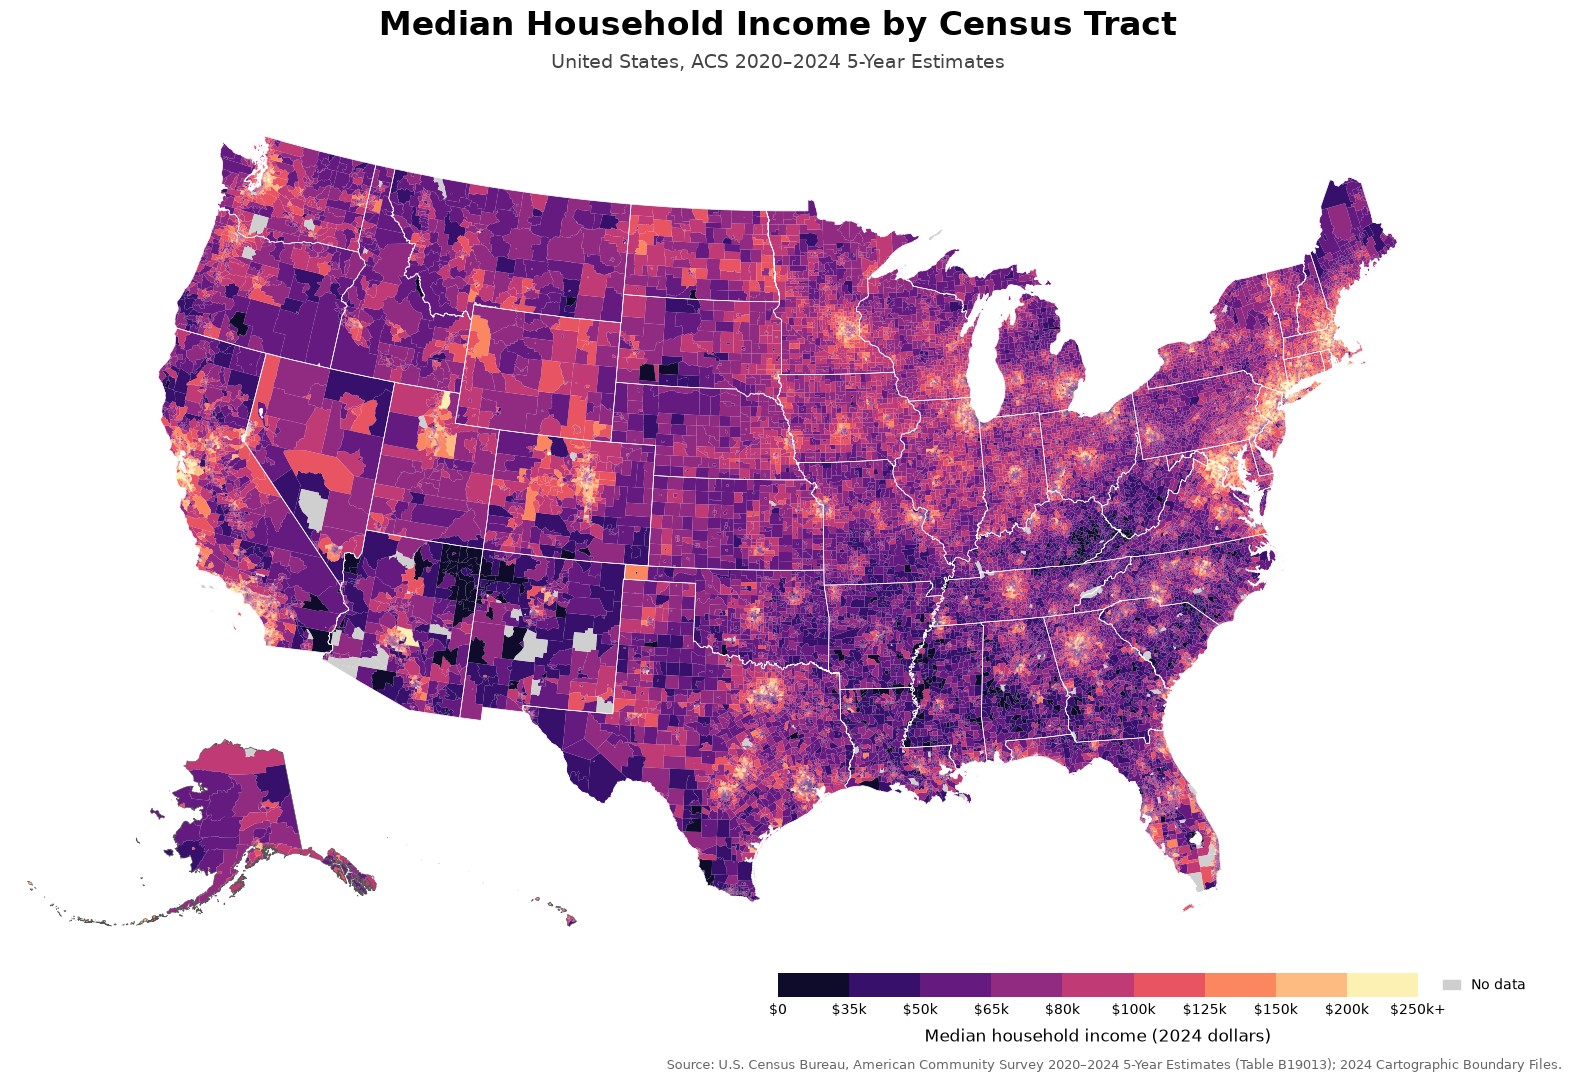

Saved figures\us_tract_median_gross_rent_2024.png


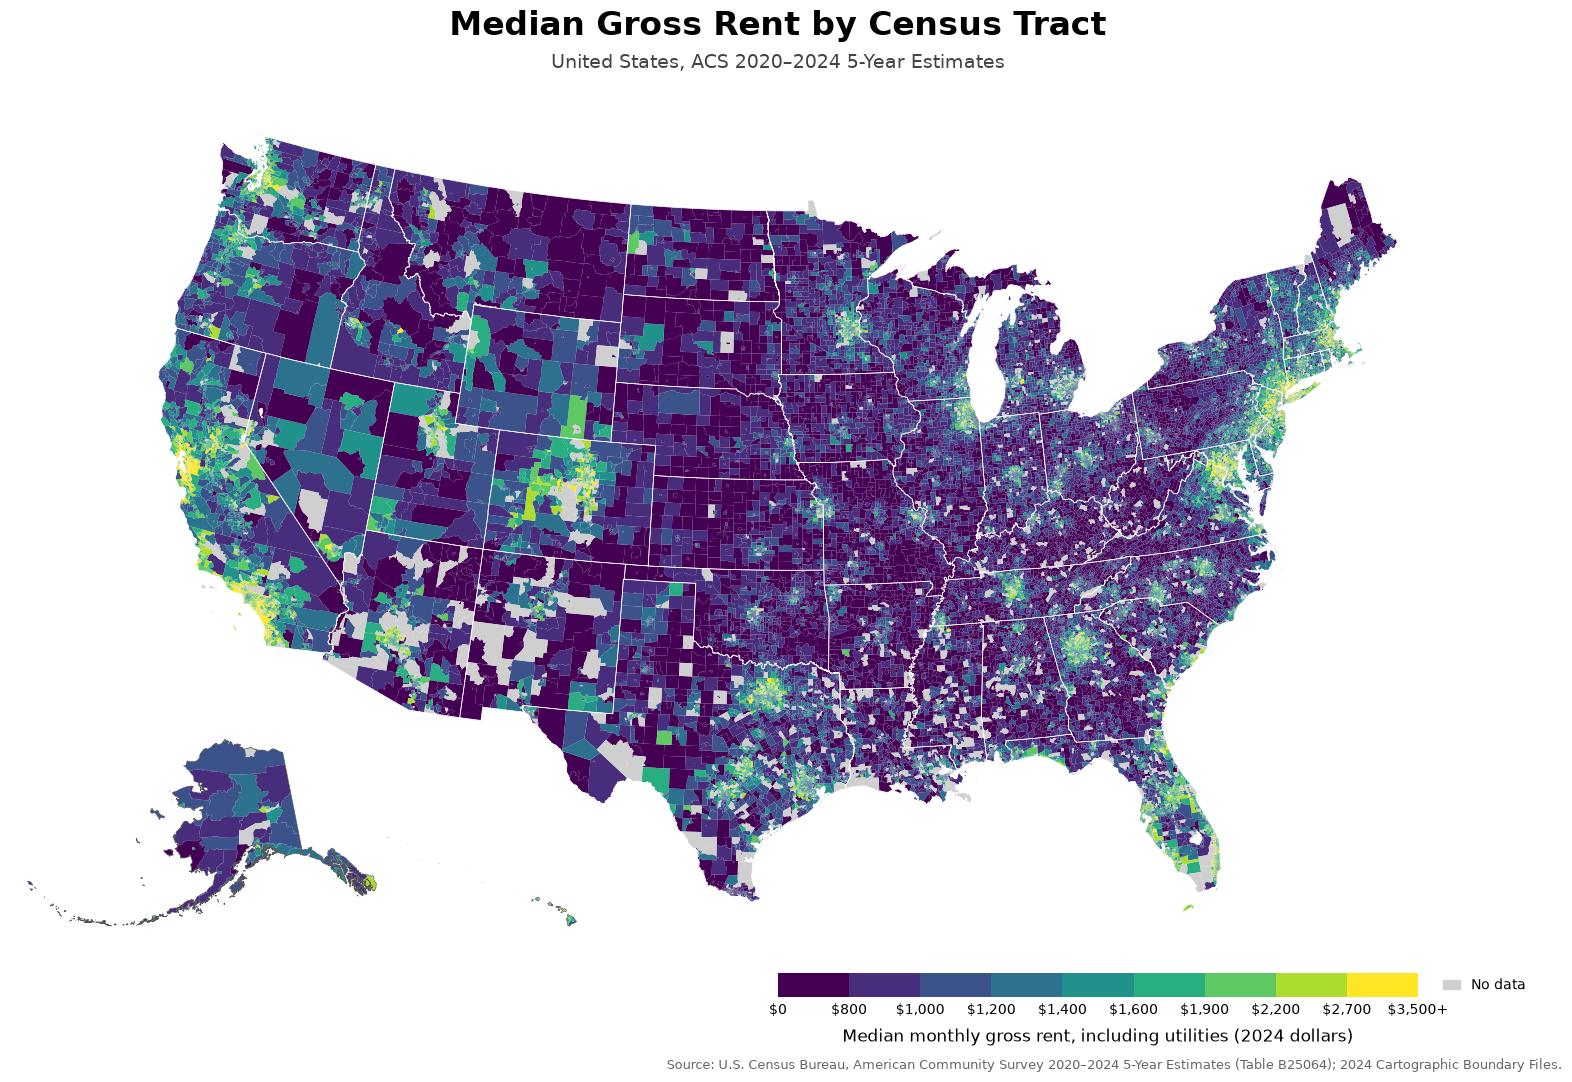

Saved figures\us_tract_rent_pct_income_2024.png


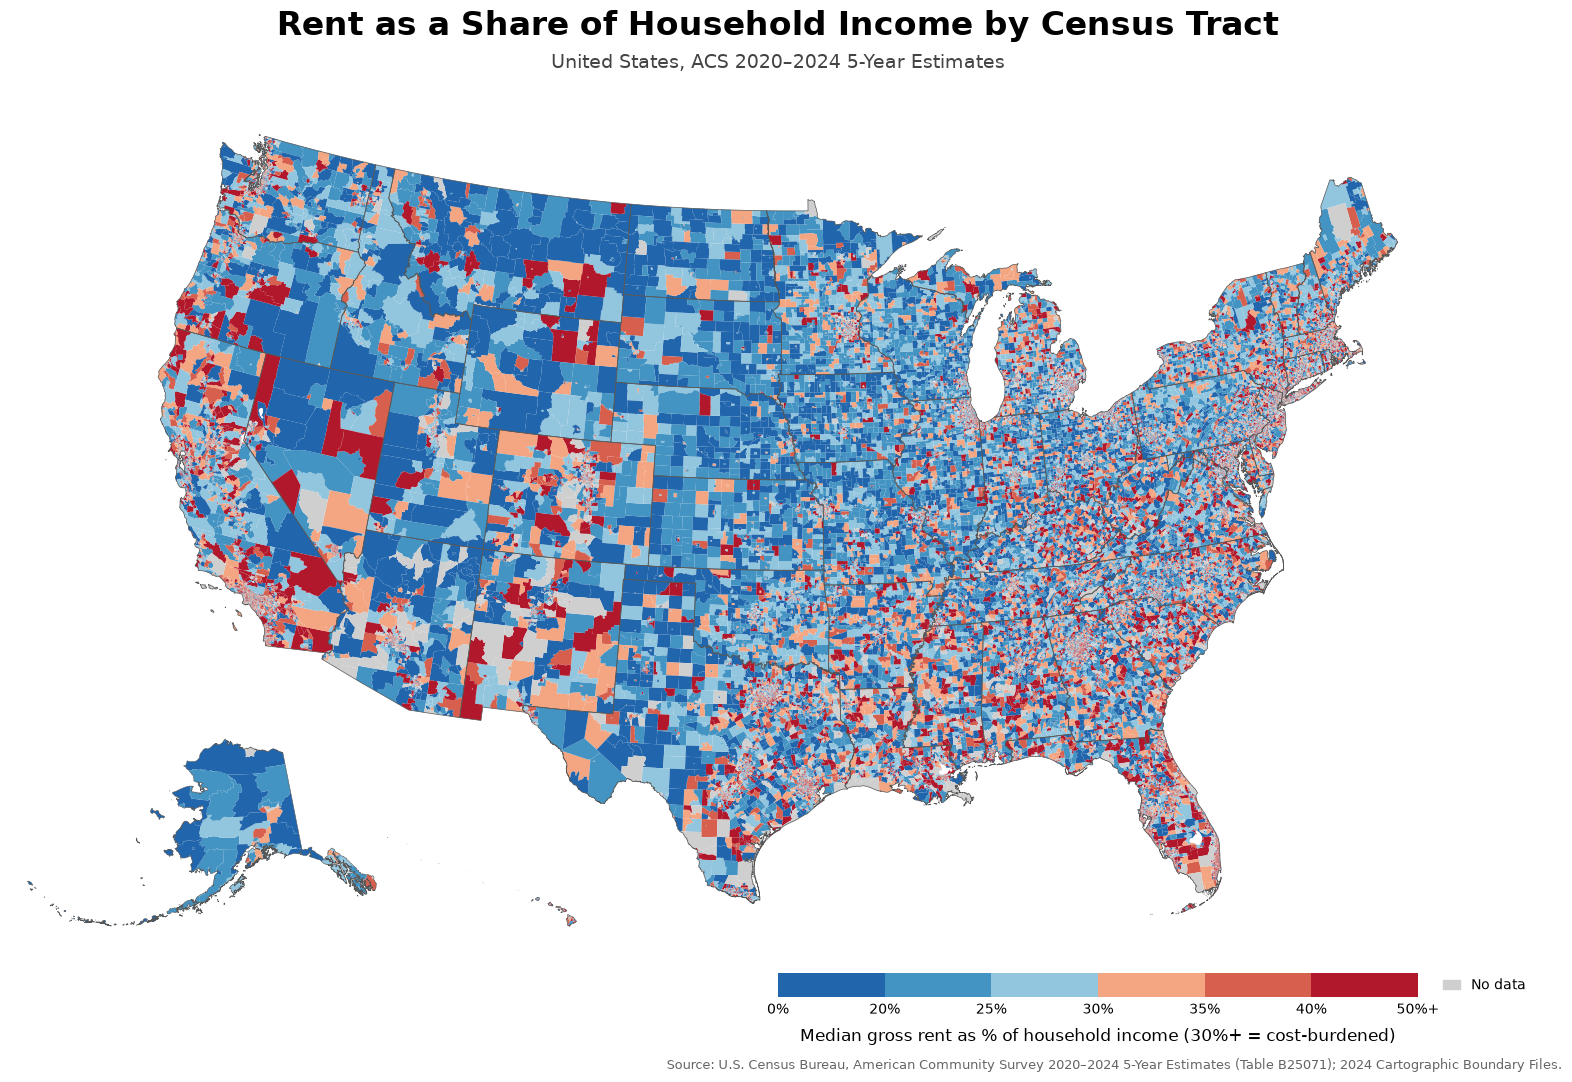

Saved figures\us_tract_median_home_value_2024.png


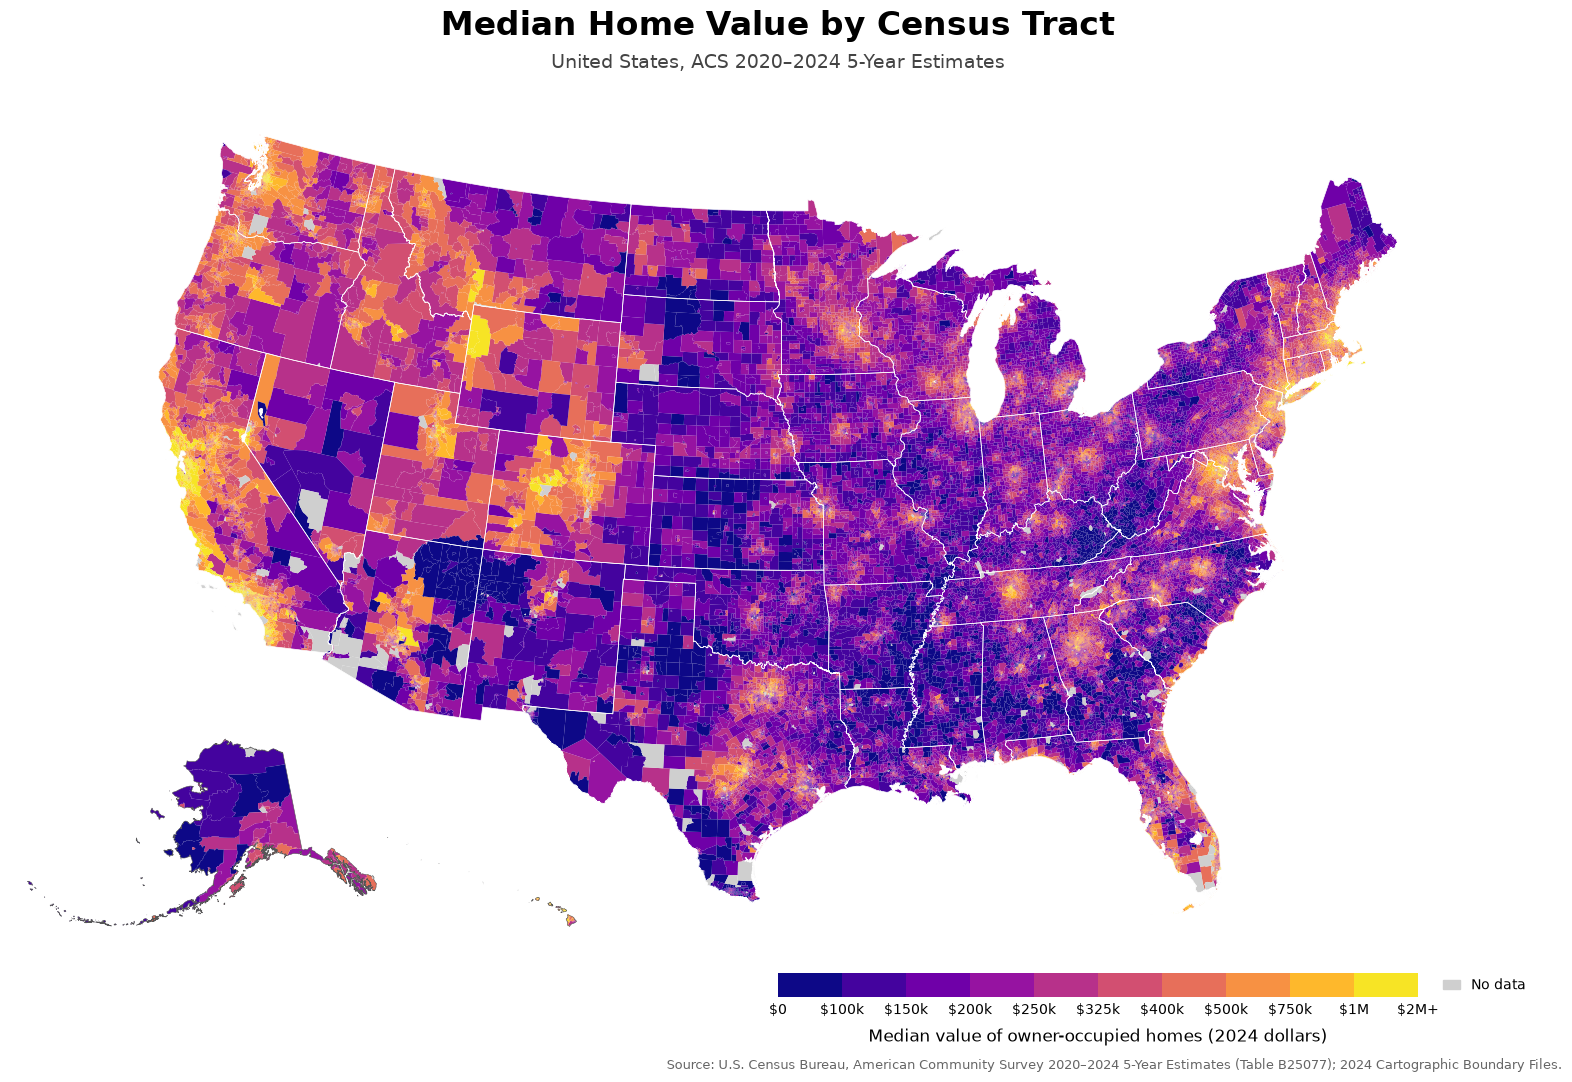

Saved figures\us_tract_median_monthly_housing_cost_2024.png


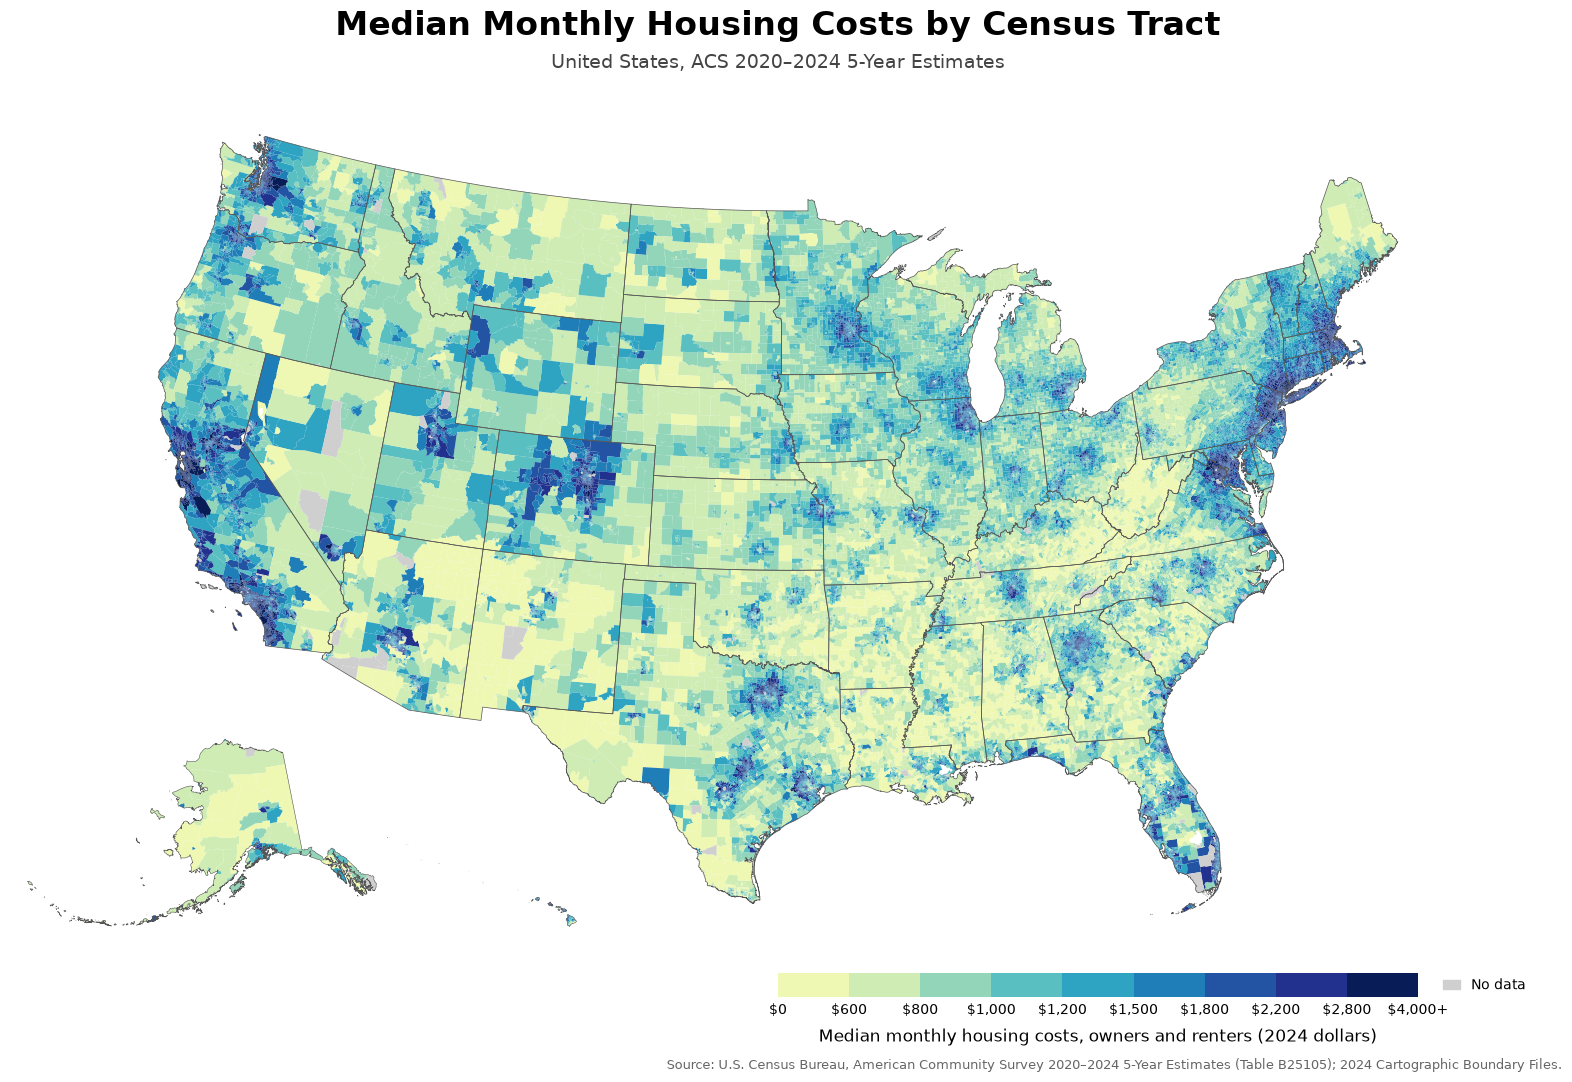

In [22]:
for col in MAPS_TO_DRAW:
    draw_us_map(col)

## 9. North Carolina maps

Saved figures\nc_tract_median_hh_income_2024.png


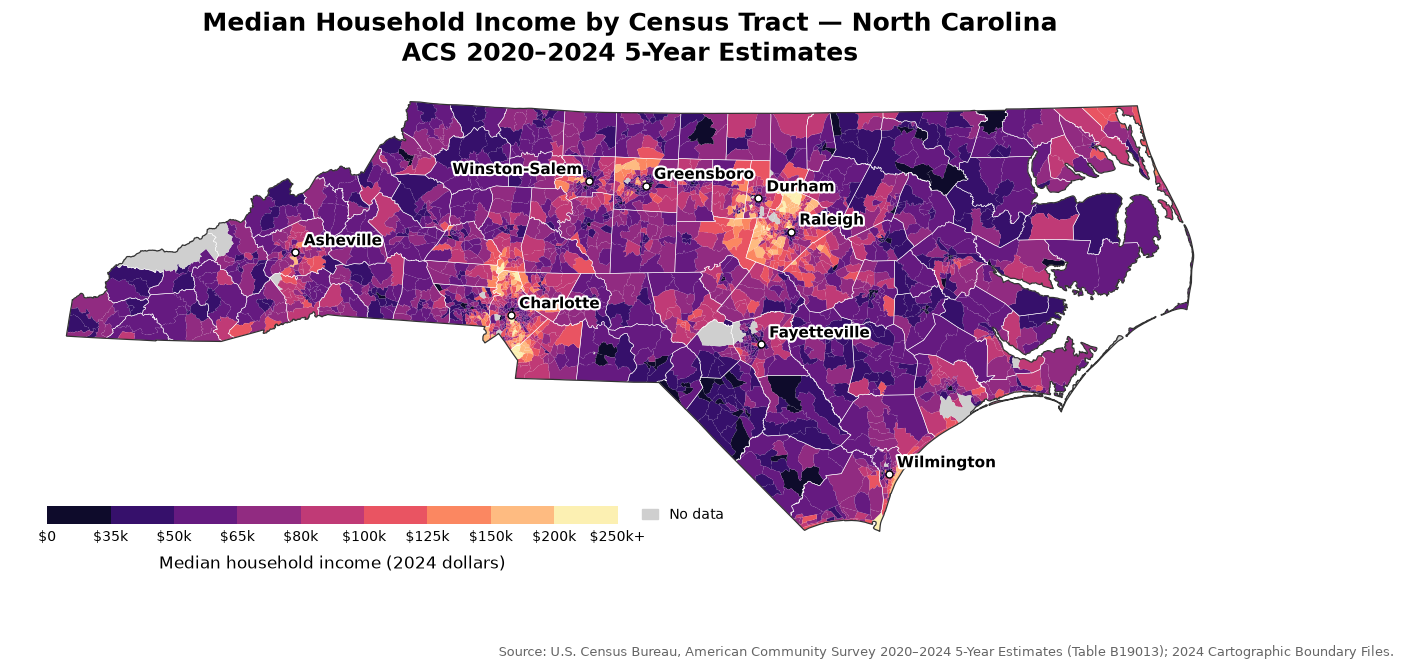

Saved figures\nc_tract_median_gross_rent_2024.png


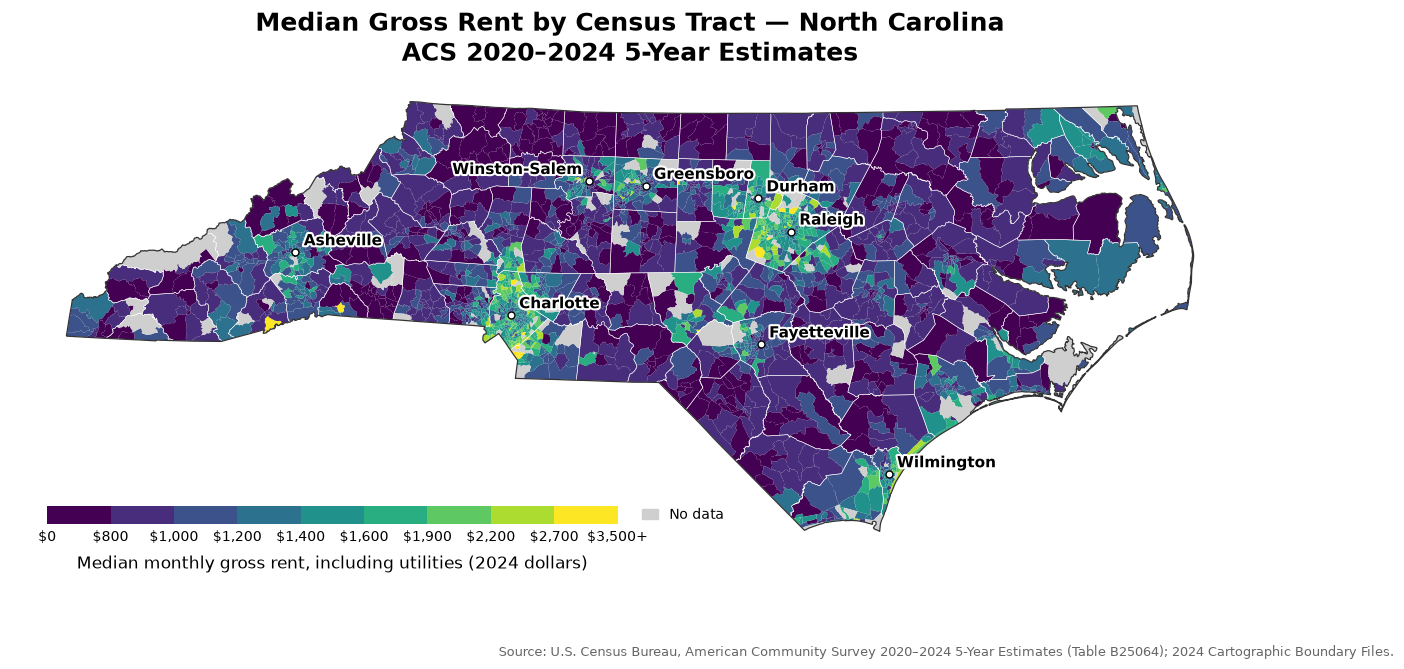

Saved figures\nc_tract_rent_pct_income_2024.png


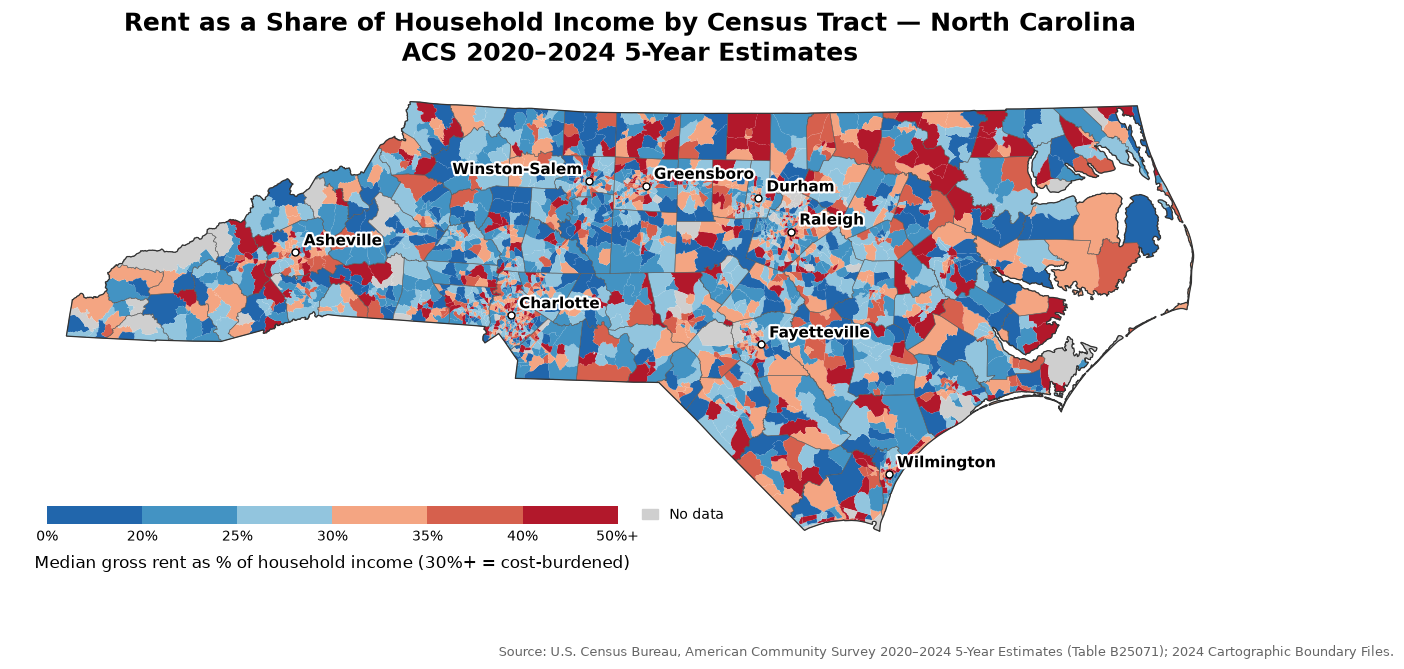

Saved figures\nc_tract_median_home_value_2024.png


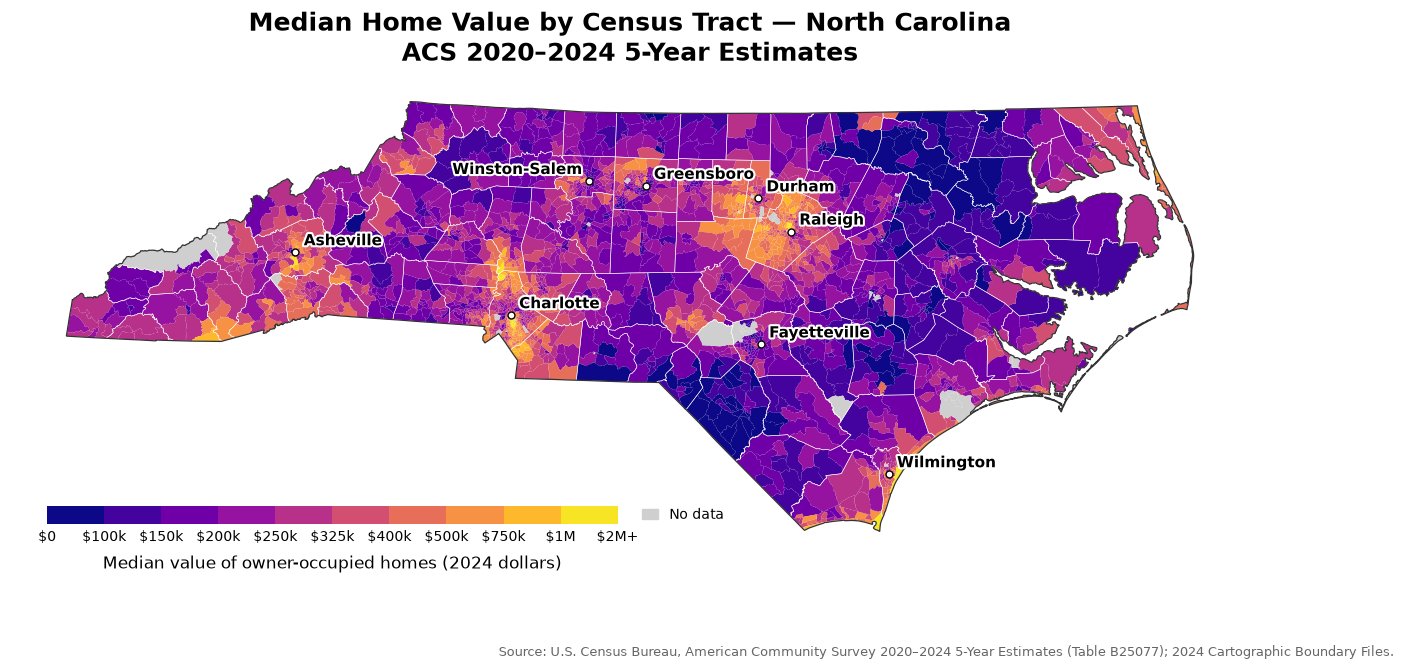

Saved figures\nc_tract_median_monthly_housing_cost_2024.png


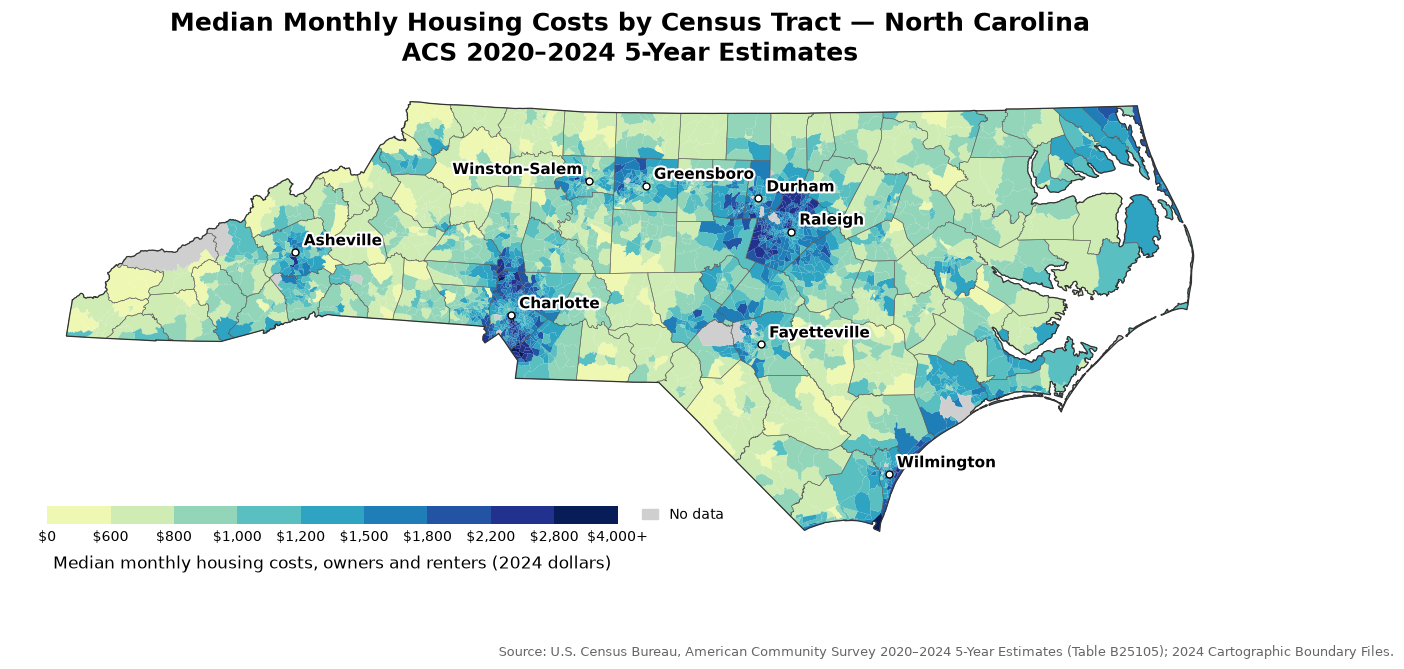

In [23]:
for col in MAPS_TO_DRAW:
    draw_nc_map(col)

## 10. Bonus: how North Carolina's tracts compare to the nation

Small-multiple distributions for all five measures, a compact companion to the maps on a poster.

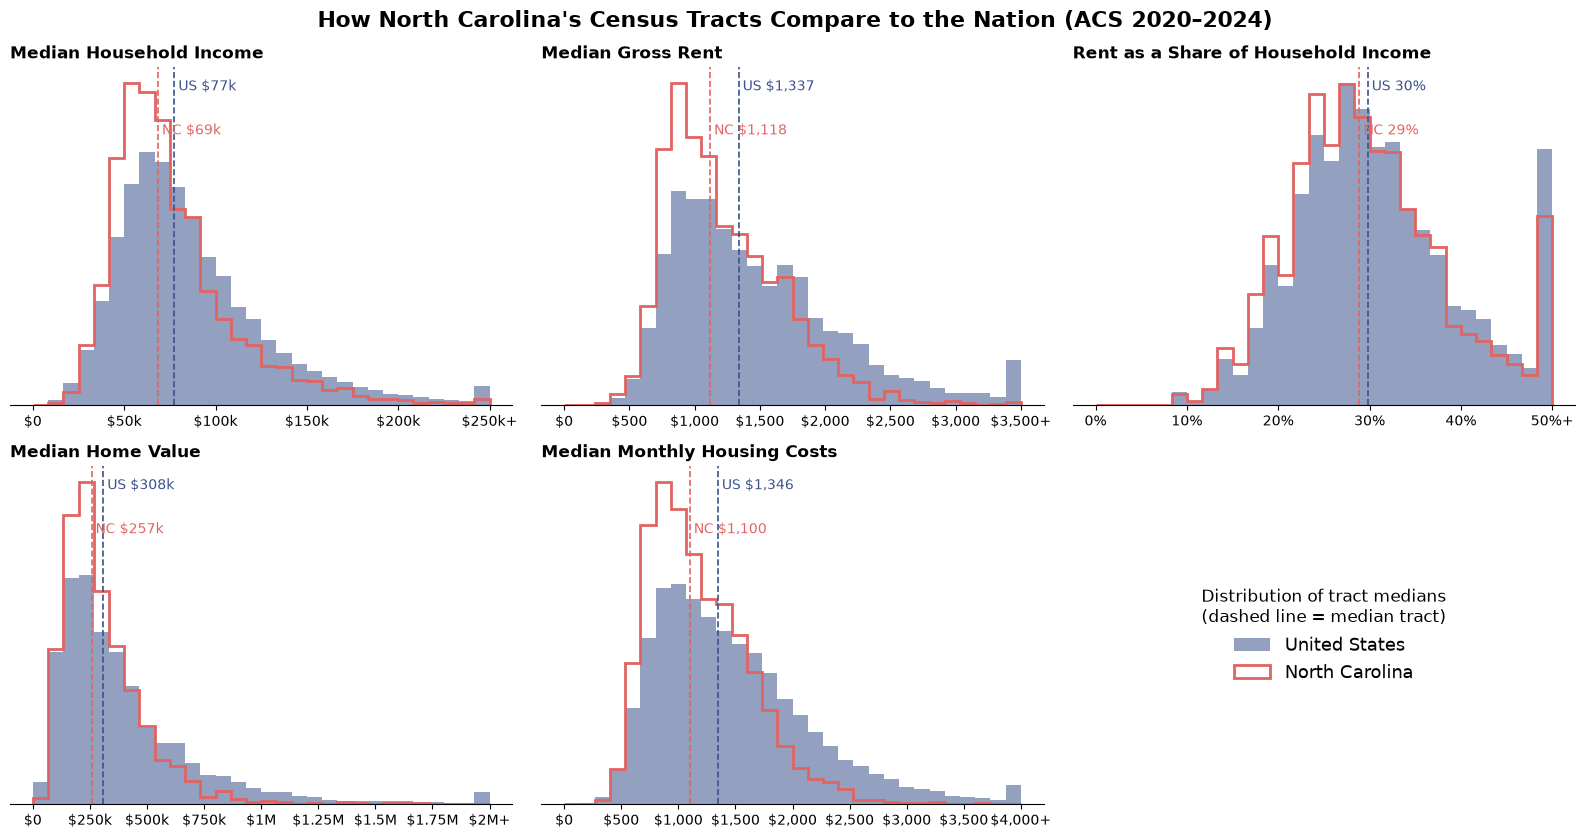

In [24]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8.5))
for ax, (col, spec) in zip(axes.flat, MAP_SPECS.items()):
    top = spec["breaks"][-1]
    bins = np.linspace(0, top, 31)
    us_vals = acs[col].dropna().clip(upper=top)
    nc_vals = nc_acs[col].dropna().clip(upper=top)
    ax.hist(us_vals, bins=bins, density=True, alpha=0.55, color="#3b528b", label="United States")
    ax.hist(nc_vals, bins=bins, density=True, histtype="step", linewidth=2, color="#e16462",
            label="North Carolina")
    ymax = ax.get_ylim()[1]
    for name, vals, color, y in [("US", us_vals, "#3b528b", 0.93), ("NC", nc_vals, "#e16462", 0.80)]:
        med = vals.median()
        ax.axvline(med, color=color, linestyle="--", linewidth=1.2)
        ax.text(med, ymax * y, f" {name} {spec['fmt'](med)}", color=color, fontsize=10)
    # default args bind this panel's spec (a plain closure would use the last spec in the loop)
    ax.xaxis.set_major_formatter(lambda v, _, s=spec, t=top: s["top_label"] if v >= t else s["fmt"](v))
    ax.set_yticks([])
    ax.spines[["top", "right", "left"]].set_visible(False)
    ax.set_title(spec["title"], fontsize=12, weight="bold", loc="left")

legend_ax = axes.flat[-1]
legend_ax.axis("off")
legend_ax.legend(*axes.flat[0].get_legend_handles_labels(), loc="center", frameon=False, fontsize=13,
                 title="Distribution of tract medians\n(dashed line = median tract)", title_fontsize=12)
fig.suptitle(f"How North Carolina's Census Tracts Compare to the Nation (ACS {YEAR - 4}–{YEAR})",
             fontsize=16, weight="bold")
fig.tight_layout()
fig.savefig(FIG_DIR / f"distributions_us_vs_nc_{YEAR}.png", dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

## Notes for the poster and next steps

- **Different universes.** Rent and rent burden describe renters, home value describes owners, and housing costs and income cover all households. A tract can be gray on the rent maps but not on the home value map (or vice versa) when it has too few renters or owners to estimate.
- **Margins of error matter at the tract level.** Tract estimates come from small samples. A common quality check is the coefficient of variation, CV = (MOE / 1.645) / estimate. Tracts with a CV above roughly 30–40% are unreliable and worth flagging if they feed into the recommender. To get MOEs for the housing measures, add the matching `_001M` variables (for example `B25064_001M`) to `VARIABLES`.
- **Gray tracts** have no estimate, usually because they contain few or no households (airports, parks, military bases, prisons, universities).
- **Tuning the bins:** use the summary table and the distribution chart to adjust each measure's `breaks` in `MAP_SPECS`, then rerun the map cells. Data is cached, so this is quick.
- **For the recommender:** `acs5_2024_tracts_clean.csv` is a ready-made tract-level feature table with all of these measures.